In [4]:
import pandas as pd
import numpy as np

df = pd.read_csv("./Data/email_preprocessed.csv")
df


,label,origin,text
0,1,Return-Path: <RickyAmes@aol.com>\nReceived: fr...,do you feel the pressure to perform and not ri...
1,0,Return-Path: <bounce-debian-mirrors=ktwarwic=s...,hi i've just updated from the gulus and i chec...
2,1,Return-Path: <7stocknews@tractionmarketing.com...,mega authenticv i a g r a discount pricec i a ...
3,1,Return-Path: <vqucsmdfgvsg@ruraltek.com>\nRece...,hey billy it was really fun going out the othe...
4,1,Return-Path: <dcube@totalink.net>\nReceived: f...,system of the home it will have the capabiliti...
...,...,...,...
53664,1,Return-Path: <hearst@cdrcorp.com>\nReceived: f...,versuchen sie unser produkt und sie werden fuh...
53665,1,Return-Path: <Merrill8783@168city.com>\nReceiv...,while we may have high expectations of our ass...
53666,0,Return-Path: <r-help-bounces@stat.math.ethz.ch...,for those who are interested i just cook a lit...
53667,0,Return-Path: <r-help-bounces@stat.math.ethz.ch...,hello as i wrote i call sqlfetch channel t stu...


In [5]:
X_full = df['text']
y_full = df['label']
y_full.value_counts()

label
1    29924
0    23745
Name: count, dtype: int64

In [6]:
from sklearn.model_selection import train_test_split

# split into 80% train 20% test, stratify tries to maintains X to y ratio for train and test sets.
X_train, X_test, y_train, y_test = train_test_split(X_full,y_full,test_size=0.2,random_state=42,stratify=y_full) 

In [7]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, StratifiedKFold

# Measures the term frequency in a document * inverse document frequency (words that appear in all emails have a low IDF)
tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    min_df= 2,
    max_df= 0.95
)

# Cross validation with 5 fold, stratified
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

def calculate_f1_score(model,X_train,y_train):
    # Calculate f1 score 
    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring='f1')

    print("Individual F1 scores:", scores)
    print("Mean F1 score:", scores.mean())
    print("Standard deviation:", scores.std())

    return scores

In [8]:
from sklearn.naive_bayes import MultinomialNB, ComplementNB
from sklearn.svm import LinearSVC

LR_model = LogisticRegression(max_iter=1000, random_state=42)

# Create model pipeline.
LR_model = Pipeline([
    ('tfidf', tfidf),
    ('lr', LR_model)
])

# Compare with different algorithms
MNB_model = Pipeline([
    ('tfidf', tfidf),
    ('mnb', MultinomialNB())
])

LinearSVM_model = Pipeline([
    ('tfidf', tfidf),
    ('linearsvm', LinearSVC(max_iter=2000,random_state=42))
])

CNB_model = Pipeline([
    ('tfidf', tfidf),
    ('cnb', ComplementNB())
])

scores = calculate_f1_score(LR_model,X_train,y_train)
scores = calculate_f1_score(MNB_model,X_train,y_train)
scores = calculate_f1_score(CNB_model,X_train,y_train)
scores = calculate_f1_score(LinearSVM_model,X_train,y_train)

Individual F1 scores: [0.99054349 0.98991579 0.98838174 0.99022869 0.98939268]
Mean F1 score: 0.9896924786108876
Standard deviation: 0.0007575644737724092
Individual F1 scores: [0.97178485 0.97314376 0.97170506 0.97323035 0.97233369]
Mean F1 score: 0.9724395393727953
Standard deviation: 0.0006481651931641535
Individual F1 scores: [0.96693248 0.96874669 0.96695615 0.9693617  0.9681461 ]
Mean F1 score: 0.9680286261363025
Standard deviation: 0.0009652186662326109
Individual F1 scores: [0.99469248 0.99416545 0.99282819 0.99469137 0.99364385]
Mean F1 score: 0.9940042666377067
Standard deviation: 0.0007049520535420809


In [9]:
from sklearn.model_selection import GridSearchCV

if False:
    # Tune parameters for SVM
    param_grid = {
        'tfidf__max_features': [10000, 20000, 30000],
        'tfidf__ngram_range': [(1, 1), (1, 2)],
        'tfidf__min_df': [1, 2, 3],
        'linearsvm__C': [0.01, 0.1, 1, 10]
    }

    grid_search = GridSearchCV(
        estimator=LinearSVM_model,
        param_grid=param_grid,
        scoring='f1',
        cv=cv,
        n_jobs=2,
        verbose=1
    )

    grid_search.fit(X_train, y_train)

In [11]:
# Using algorithm with best f1 results and tuned hyperparameters with gridsearchcv
tfidf = TfidfVectorizer(
    max_features=30000,
    ngram_range=(1, 2),
    min_df= 1,
    max_df= 0.95
)

LinearSVM_model = Pipeline([
    ('tfidf', tfidf),
    ('linearsvm', LinearSVC(max_iter=2000,random_state=42, C=1))
])

scores = calculate_f1_score(LinearSVM_model,X_train,y_train)

Individual F1 scores: [0.99593961 0.99499896 0.99397215 0.99489743 0.99510264]
Mean F1 score: 0.9949821568381207
Standard deviation: 0.0006259108286142659


In [14]:
from sklearn.metrics import classification_report

# Evaluate against test data
LinearSVM_model.fit(X_train, y_train)
y_pred = LinearSVM_model.predict(X_test)

print(classification_report(y_test,y_pred))


              precision    recall  f1-score   support

           0       1.00      0.99      0.99      4749
           1       0.99      1.00      1.00      5985

    accuracy                           0.99     10734
   macro avg       0.99      0.99      0.99     10734
weighted avg       0.99      0.99      0.99     10734



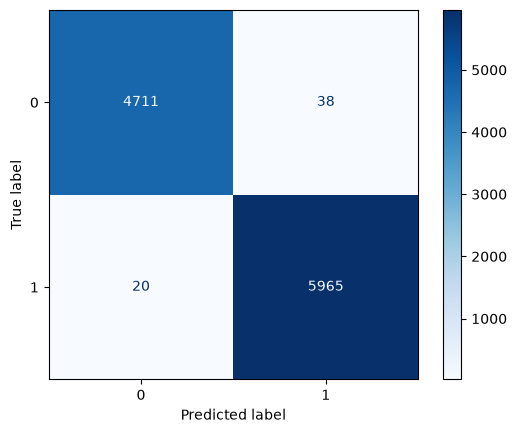

In [15]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=LinearSVM_model.classes_
)

disp.plot(cmap='Blues')
plt.show()

In [16]:
# test with email that model has never seen.
test_emails = [
    "Congratulations! You have won a free iPhone. Click here now!",
    "Hi, just checking whether we are still meeting tomorrow.",
    "URGENT! Claim your cash prize now!"
]

predictions = LinearSVM_model.predict(test_emails)

for email, prediction in zip(test_emails, predictions):
    print(f"Email: {email}")
    print(f"Prediction: {prediction}")
    print()

Email: Congratulations! You have won a free iPhone. Click here now!
Prediction: 1

Email: Hi, just checking whether we are still meeting tomorrow.
Prediction: 1

Email: URGENT! Claim your cash prize now!
Prediction: 1



Model incorrectly identified ham email as spam, investigate why

In [17]:
# Check misclassified emails
errors = pd.DataFrame({
    'text': X_test,
    'actual': y_test,
    'predicted': y_pred
})

errors = errors[errors['actual'] != errors['predicted']]

print(errors.head(20))

                                                    text  actual  predicted
44346  smylers reported i was with you right up until...       0          1
1251   hi guys how could i exec a 'dir' command on a ...       1          0
30783  all this sermonising does no good um except th...       0          1
51575  the body grows and develops gradually not over...       0          1
43620  as an administrator you might want to keep an ...       1          0
29488  mathcad code failed to attach last time here i...       0          1
22887  constant contact http www constantcontact com ...       0          1
48232  protect serve not even escapenumber year olds ...       0          1
23971  the huge world of warcraft escapenumber escape...       1          0
39714  http www amazon com gp product escapelong esca...       0          1
29036  legal beagle sourcers court patent feb reduce ...       0          1
10420  je serai absent e à partir du escapenumber esc...       0          1
28498  for f

In [18]:
email = ["Hi, just checking whether we are still meeting tomorrow."]

print(LinearSVM_model.predict(email))
print(LinearSVM_model.decision_function(email))

[1]
[0.13178721]


In [21]:
tfidf = LinearSVM_model.named_steps['tfidf']
svm = LinearSVM_model.named_steps['linearsvm']

X_email = tfidf.transform(email)

feature_names = tfidf.get_feature_names_out()

contributions = X_email.multiply(svm.coef_).toarray().flatten()

top_features = sorted(
    zip(feature_names, contributions),
    key=lambda x: abs(x[1]),
    reverse=True
)

print(top_features[:10])

[('hi', np.float64(-0.20234492709151924)), ('checking', np.float64(-0.13365071309679366)), ('just', np.float64(-0.11458109515405838)), ('tomorrow', np.float64(-0.09842084184614132)), ('we are', np.float64(0.08036828491111421)), ('checking whether', np.float64(-0.06155195165144278)), ('still', np.float64(-0.05388281373699536)), ('whether', np.float64(-0.05360506211789084)), ('are', np.float64(0.040330025299780706)), ('we', np.float64(-0.037009135083935746))]


In [23]:
svm = LinearSVM_model.named_steps['linearsvm']

print("Intercept:", svm.intercept_)

print("Sum of contributions:", contributions.sum())
print("Intercept:", svm.intercept_[0])
print("Total decision score:", contributions.sum() + svm.intercept_[0])

Intercept: [0.81195757]
Sum of contributions: -0.6801703584507497
Intercept: 0.8119575722968989
Total decision score: 0.13178721384614922


Observation: Insufficient ham feature to overcome bias.

In [ ]:
# Try with balanced class weight 
LinearSVM_model = Pipeline([
    ('tfidf', tfidf),
    ('linearsvm', LinearSVC(max_iter=2000,random_state=42, C=1, class_weight='balanced'))
])

# Evaluate against test data
LinearSVM_model.fit(X_train, y_train)
y_pred = LinearSVM_model.predict(X_test)

print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       1.00      0.99      0.99      4749
           1       0.99      1.00      1.00      5985

    accuracy                           0.99     10734
   macro avg       0.99      0.99      0.99     10734
weighted avg       0.99      0.99      0.99     10734



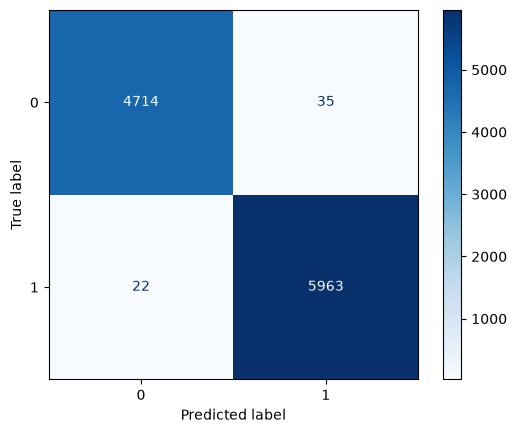

In [26]:
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=LinearSVM_model.classes_
)

disp.plot(cmap='Blues')
plt.show()

In [27]:
test_emails = [
    "Congratulations! You have won a free iPhone. Click here now!",
    "Hi, just checking whether we are still meeting tomorrow.",
    "URGENT! Claim your cash prize now!"
]

predictions = LinearSVM_model.predict(test_emails)

for email, prediction in zip(test_emails, predictions):
    print(f"Email: {email}")
    print(f"Prediction: {prediction}")
    print()

Email: Congratulations! You have won a free iPhone. Click here now!
Prediction: 1

Email: Hi, just checking whether we are still meeting tomorrow.
Prediction: 1

Email: URGENT! Claim your cash prize now!
Prediction: 1



In [28]:
email = ["Hi, just checking whether we are still meeting tomorrow."]

print(LinearSVM_model.predict(email))
print(LinearSVM_model.decision_function(email))

[1]
[0.11350759]


Still not enough to overcome bias.

In [ ]:

test_emails = [
    # HAM (0)
    "can you send me the updated version of the presentation ",
    "hey how is it going ",
    "ill be working from home this friday let me know if anything urgent comes up ",
    "the package arrived this morning everything looks good ",
    "are you available for lunch next wednesday ",
    "ive reviewed the report and added a few comments ",
    "sorry for the late reply i was away from my computer ",
    "the body grows and develops gradually not over ",

    # SPAM (1)
    # "congratulations you have been selected to receive a free holiday package ",
    # "your account requires immediate verification click the link to avoid suspension ",
    # "earn extra income from home with no experience required apply today ",
    # "limited time offer get escapenumber percent off all premium products ",
    # "you have an unpaid invoice make your payment now to avoid additional charges ",
    # "claim your exclusive cash reward before this opportunity expires ",
    # "your loan application has been pre approved contact us to receive your funds ",
    # "unlock unlimited access to premium content with our special membership offer ",
    # "act now your chance to win a brand new smartphone is about to expire ",
    # "dear customer you qualify for a special discount on your next purchase "
]


predictions = LinearSVM_model.predict(test_emails)

for email, prediction in zip(test_emails, predictions):
    print(f"Email: {email}")
    print(f"Prediction: {prediction}")
    print()

Email: hi i have to use r to find out the escapenumber confidence interval for the sensitivity and specificity of the following diagnostic test a particular diagnostic test for multiple sclerosis was conducted on escapenumber ms patients and escapenumber healthy subjects escapenumber ms patients were classified as healthy and escapenumber healthy subjects were classified as suffering from the ms furthermore i need to find the number of ms patients required for a sensitivity of escapenumber is there a simple r command which can do that for me i am completely new to r help please jochen view this message in context http www nabble com confidence intervals help tfescapenumber html aescapenumber sent from the r help mailing list archive at nabble com r help stat math ethz ch mailing list https stat ethz ch mailman listinfo r help please do read the posting guide http www r project org posting guide html and provide commented minimal self contained reproducible code 
Prediction: 0

Email: g

Model incorrectly identifies most of the short emails.

In [78]:
df['email_length'] = df['text'].str.split().str.len()

print(
    df.groupby('label')['email_length'].describe()
)

print(
    df.groupby('label')['email_length'].mean()
)

         count        mean         std  min     25%    50%    75%       max
label                                                                      
0      23745.0  380.654117  916.197596  1.0  130.00  215.0  390.0  101984.0
1      29924.0  185.019516  310.416918  1.0   57.75  119.0  242.0   25393.0
label
0    380.654117
1    185.019516
Name: email_length, dtype: float64


In [79]:
errors = pd.DataFrame({
    'text': X_test,
    'actual': y_test,
    'predicted': y_pred
})

errors['email_length'] = errors['text'].str.split().str.len()

errors['result'] = errors.apply(
    lambda row: (
        'True Positive' if row['actual'] == 1 and row['predicted'] == 1
        else 'True Negative' if row['actual'] == 0 and row['predicted'] == 0
        else 'False Positive' if row['actual'] == 0 and row['predicted'] == 1
        else 'False Negative'
    ),
    axis=1
)

print(
    errors.groupby('result')['email_length'].describe()
)

                 count        mean         std  min    25%    50%     75%  \
result                                                                      
False Negative    22.0  273.818182  220.568235  1.0   64.0  288.5  434.25   
False Positive    35.0  138.228571  111.252253  9.0   37.5  116.0  215.00   
True Negative   4714.0  381.042851  702.738090  4.0  130.0  217.0  391.75   
True Positive   5963.0  180.713399  219.832111  1.0   57.0  117.0  238.50   

                    max  
result                   
False Negative    787.0  
False Positive    398.0  
True Negative   15201.0  
True Positive    4490.0  


In [80]:
errors['length_group'] = pd.cut(
    errors['email_length'],
    bins=[0, 50, 200, 500, float('inf')],
    labels=['Short', 'Medium', 'Long', 'Very Long']
)

print(
    pd.crosstab(
        errors['length_group'],
        errors['actual'].map({0: 'Ham', 1: 'Spam'}),
        normalize='index'
    )
)

actual             Ham      Spam
length_group                    
Short         0.089082  0.910918
Medium        0.419766  0.580234
Long          0.564035  0.435965
Very Long     0.655981  0.344019


In [81]:
from sklearn.metrics import precision_score, recall_score, f1_score

for name, group in errors.groupby('length_group', observed=True):

    print(f"\n{name} Emails (n={len(group)})")

    for label, class_name in [(0, 'Ham'), (1, 'Spam')]:
        precision = precision_score(
            group['actual'], group['predicted'],
            pos_label=label, zero_division=0
        )

        recall = recall_score(
            group['actual'], group['predicted'],
            pos_label=label, zero_division=0
        )

        f1 = f1_score(
            group['actual'], group['predicted'],
            pos_label=label, zero_division=0
        )

        print(f"{class_name}:")
        print(f"  Precision: {precision:.4f}")
        print(f"  Recall:    {recall:.4f}")
        print(f"  F1:        {f1:.4f}")


Short Emails (n=1493)
Ham:
  Precision: 0.9683
  Recall:    0.9173
  F1:        0.9421
Spam:
  Precision: 0.9920
  Recall:    0.9971
  F1:        0.9945

Medium Emails (n=4948)
Ham:
  Precision: 0.9976
  Recall:    0.9942
  F1:        0.9959
Spam:
  Precision: 0.9958
  Recall:    0.9983
  F1:        0.9970

Long Emails (n=3014)
Ham:
  Precision: 0.9947
  Recall:    0.9929
  F1:        0.9938
Spam:
  Precision: 0.9909
  Recall:    0.9932
  F1:        0.9920

Very Long Emails (n=1279)
Ham:
  Precision: 0.9953
  Recall:    1.0000
  F1:        0.9976
Spam:
  Precision: 1.0000
  Recall:    0.9909
  F1:        0.9954


Short ham emails have a low recall and F1 score compared to other categories 
Need more data on short ham emails 